# 03 - Feature Engineering
**Goal:** build the best input set for the models, and prove each choice with cross-validation.

Steps: set target -> clean (constant / redundant) -> rank -> try encodings -> create new features -> try PCA -> compare feature sets -> save.

> Every decision is fitted on **train only**. CV = 5-fold, metric = F1 (phishing = positive class).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif, VarianceThreshold, chi2, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
IN = Path("..") / "Artifacts" / "notebooks"
TARGET = "Result"
train = pd.read_csv(IN / "train.csv")
test = pd.read_csv(IN / "test.csv")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 1. Fix the target
Map `-1 -> 1` (phishing = positive class) and `1 -> 0`. Metrics like recall and ROC-AUC then answer "how well do we catch phishing?".

In [2]:
def split_xy(df):
    return df.drop(columns=[TARGET]), (df[TARGET] == -1).astype(int)

X_train, y_train = split_xy(train)
X_test, y_test = split_xy(test)
print(y_train.value_counts().rename({1: "phishing", 0: "legit"}))

def rf(): return RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
def lr(): return make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=1000))
def cv_f1(model, X): return cross_val_score(model, X, y_train, cv=CV, scoring="f1", n_jobs=-1).mean()

base_rf, base_lr = cv_f1(rf(), X_train), cv_f1(lr(), X_train)
print(f"BASELINE (all {X_train.shape[1]} features)  RF F1={base_rf:.4f} | LogReg F1={base_lr:.4f}")

Result
legit       4926
phishing    3918
Name: count, dtype: int64


BASELINE (all 30 features)  RF F1=0.9650 | LogReg F1=0.9302


> **Reading the output:** Reference scores with all 30 features: RandomForest F1 = 0.965, one-hot LogisticRegression F1 = 0.930. Every later change is judged against these two numbers.

## 2. Constant & near-constant features
A feature with (almost) one value cannot separate classes.

In [3]:
constant = X_train.columns[VarianceThreshold(0.0).fit(X_train).variances_ == 0].tolist()
dominant = X_train.apply(lambda s: s.value_counts(normalize=True).iloc[0]).sort_values(ascending=False)
print("constant features:", constant)
print("\nmost dominant value share (top 6):"); print(dominant.head(6).round(3))

constant features: []

most dominant value share (top 6):
RightClick                  0.956
Iframe                      0.908
Redirect                    0.885
on_mouseover                0.880
double_slash_redirecting    0.872
Shortining_Service          0.871
dtype: float64


> **Reading the output:** No feature is constant. The most dominant ones are `RightClick` (95.6%) and `Iframe` (90.8%). They are near-constant but not removable by a variance rule, so we leave them for the ranking and CV tests.

## 3. Redundant (highly correlated) features
How many features would we drop at different correlation thresholds?

In [4]:
corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))

def redundant_at(th): return [c for c in upper.columns if (upper[c] > th).any()]

rows = []
for th in [0.6, 0.7, 0.8, 0.9]:
    cols = [c for c in X_train.columns if c not in redundant_at(th)]
    rows.append({"threshold": th, "n_dropped": X_train.shape[1] - len(cols), "n_kept": len(cols),
                 "cv_f1_rf": cv_f1(rf(), X_train[cols])})
thr = pd.DataFrame(rows).set_index("threshold")
print("pairs above 0.8:"); print(upper.stack()[lambda s: s > 0.8].round(3))
thr.round(4)

pairs above 0.8:
Shortining_Service  double_slash_redirecting    0.837
Favicon             port                        0.804
                    popUpWidnow                 0.940
dtype: float64


,n_dropped,n_kept,cv_f1_rf
threshold,,,
0.6,9,21,0.9605
0.7,7,23,0.9628
0.8,3,27,0.9653
0.9,1,29,0.9638


> **Reading the output:** Only 3 pairs correlate above 0.8. Dropping at 0.8 gives RF F1 = 0.9653, the same as all features (0.9650), while dropping at 0.6 loses accuracy (0.9605). Redundant features do no harm to the trees, so aggressive pruning is not needed.

## 4. Rank features with 4 methods
Chi-square, mutual information, random-forest importance and permutation importance (on a held-out slice).

In [5]:
chi_scores = pd.Series(chi2(X_train - X_train.min(), y_train)[0], index=X_train.columns)   # chi2 needs values >= 0
mi = pd.Series(mutual_info_classif(X_train, y_train, discrete_features=True, random_state=42), index=X_train.columns)

forest = rf().fit(X_train, y_train)
rf_imp = pd.Series(forest.feature_importances_, index=X_train.columns)

Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)
perm_model = rf().fit(Xa, ya)
perm = pd.Series(permutation_importance(perm_model, Xb, yb, scoring="f1", n_repeats=5, random_state=42, n_jobs=-1).importances_mean,
                 index=X_train.columns)

ranking = pd.DataFrame({"chi2": chi_scores, "mutual_info": mi, "rf_importance": rf_imp, "permutation": perm})
rank_pos = ranking.rank(ascending=False)
ranking["avg_rank"] = rank_pos.mean(axis=1)
ranking = ranking.sort_values("avg_rank")
ranking.head(12).round(4)

,chi2,mutual_info,rf_importance,permutation,avg_rank
SSLfinal_State,3022.2944,0.3467,0.3197,0.1166,1.25
URL_of_Anchor,2368.1823,0.3326,0.2500,0.1294,1.75
Prefix_Suffix,1864.3508,0.0855,0.0379,0.0288,4.00
web_traffic,565.9172,0.0778,0.0708,0.0289,4.25
having_Sub_Domain,502.0887,0.0779,0.0695,0.0184,5.00
Links_in_tags,354.4952,0.0320,0.0439,0.0180,6.50
SFH,609.0204,0.0255,0.0202,0.0102,6.50
Request_URL,448.8677,0.0314,0.0177,0.0046,9.25
Domain_registeration_length,578.8876,0.0245,0.0167,0.0038,9.75
age_of_domain,125.4275,0.0076,0.0165,0.0067,10.50


> **Reading the output:** All four methods agree on the top: `SSLfinal_State` (avg rank 1.25) and `URL_of_Anchor` (1.75), then `Prefix_Suffix`, `web_traffic`, `having_Sub_Domain`. Permutation importance, the most trustworthy, shows shuffling `URL_of_Anchor` costs 0.13 F1.

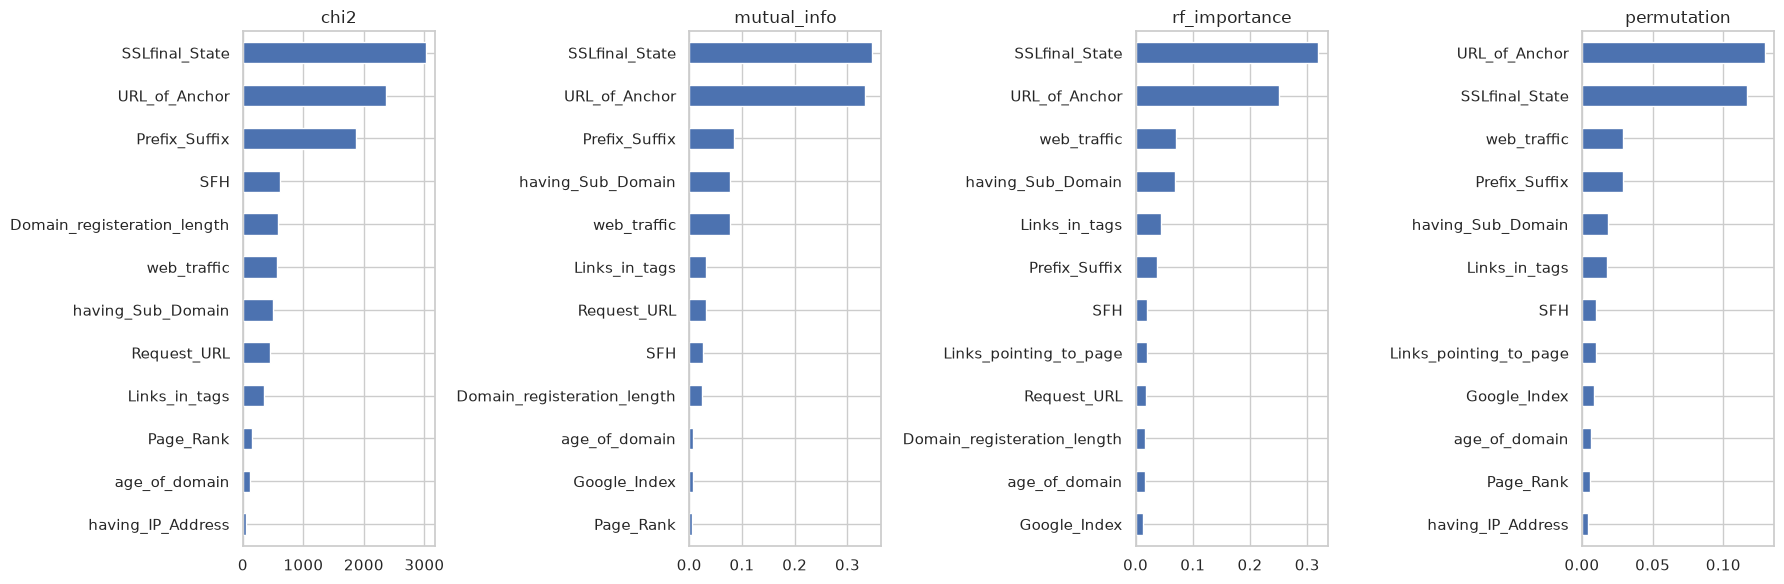

rank correlation between methods:
               chi2  mutual_info  rf_importance  permutation
chi2           1.00         0.96           0.83         0.79
mutual_info    0.96         1.00           0.89         0.88
rf_importance  0.83         0.89           1.00         0.94
permutation    0.79         0.88           0.94         1.00


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=False)
for ax, col in zip(axes, ["chi2", "mutual_info", "rf_importance", "permutation"]):
    ranking[col].sort_values().tail(12).plot(kind="barh", ax=ax, title=col)
plt.tight_layout(); plt.show()
print("rank correlation between methods:"); print(rank_pos.corr(method="spearman").round(2))

> **Reading the output:** The bars show a steep drop after the top 2, then a long tail of weak features. Spearman rank correlations of 0.79-0.96 between methods show the ranking is stable and not an artifact of one method.

## 5. Encoding: treat values as numbers or as categories?
`-1/0/1` could be ordered numbers or three unrelated categories. One-hot lets a model treat `0` as its own state.

In [7]:
ohe_cols = pd.get_dummies(X_train.astype(str)).astype(int)
enc = pd.DataFrame({
    "numeric (as is)": {"RF": base_rf, "LogReg": base_lr},
    "one-hot": {"RF": cv_f1(rf(), ohe_cols),
                "LogReg": cross_val_score(LogisticRegression(max_iter=1000), ohe_cols, y_train, cv=CV, scoring="f1", n_jobs=-1).mean()},
})
print("one-hot width:", ohe_cols.shape[1], "columns")
enc.round(4)

one-hot width: 68 columns


,numeric (as is),one-hot
RF,0.9650,0.9657
LogReg,0.9302,0.9302


> **Reading the output:** One-hot (68 columns) gives RF 0.9657 vs 0.9650 numeric, and LogReg 0.9302 for both. The encoding barely matters, so we keep the simpler numeric columns.

## 6. Create new features
Ideas: count the red flags / neutral / safe values per site, a weighted score, and an interaction of the two strongest features.

In [8]:
top2 = ranking.index[:2].tolist()
print("top-2 features used for interaction:", top2)

def add_features(X: pd.DataFrame) -> pd.DataFrame:
    base = X[[c for c in X.columns if c in X_train.columns]]
    out = X.copy()
    out["n_suspicious"] = (base == -1).sum(axis=1)
    out["n_neutral"] = (base == 0).sum(axis=1)
    out["n_safe"] = (base == 1).sum(axis=1)
    out["flag_balance"] = out["n_safe"] - out["n_suspicious"]
    out[f"{top2[0]}_x_{top2[1]}"] = base[top2[0]] * base[top2[1]]
    return out

X_new = add_features(X_train)
new_cols = [c for c in X_new.columns if c not in X_train.columns]
print("new features:", new_cols)

res = pd.DataFrame({
    "original": {"RF": base_rf, "LogReg": base_lr},
    "original + new": {"RF": cv_f1(rf(), X_new), "LogReg": cv_f1(lr(), X_new)},
})
res.round(4)

top-2 features used for interaction: ['SSLfinal_State', 'URL_of_Anchor']
new features: ['n_suspicious', 'n_neutral', 'n_safe', 'flag_balance', 'SSLfinal_State_x_URL_of_Anchor']


,original,original + new
RF,0.9650,0.9641
LogReg,0.9302,0.9283


> **Reading the output:** The new features did not help: RF drops from 0.9650 to 0.9641 and LogReg from 0.9302 to 0.9283. Trees can already combine the original columns, so the red-flag counts add no new information.

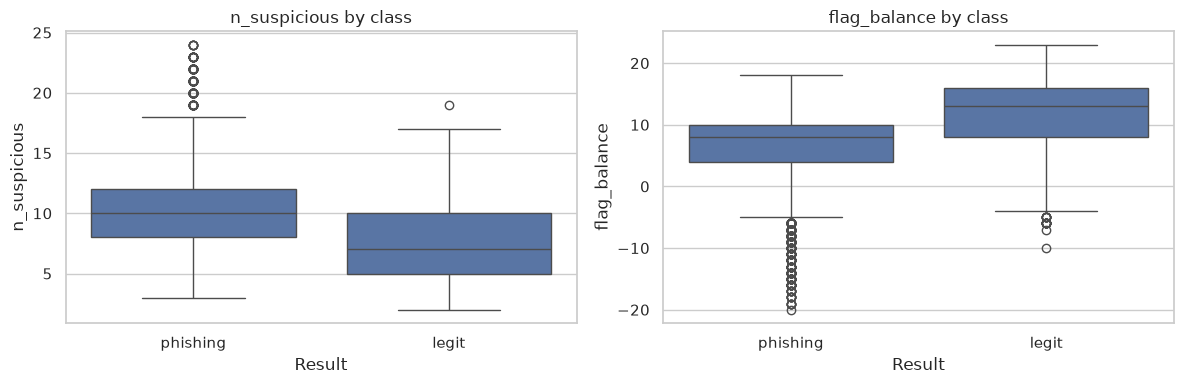

importance of new features (RF fitted on original + new):


flag_balance                      0.0691
n_safe                            0.0639
n_suspicious                      0.0531
SSLfinal_State_x_URL_of_Anchor    0.0253
n_neutral                         0.0182
dtype: float64

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=y_train.map({0: "legit", 1: "phishing"}), y=X_new["n_suspicious"], ax=ax[0]); ax[0].set_title("n_suspicious by class")
sns.boxplot(x=y_train.map({0: "legit", 1: "phishing"}), y=X_new["flag_balance"], ax=ax[1]); ax[1].set_title("flag_balance by class")
plt.tight_layout(); plt.show()
print("importance of new features (RF fitted on original + new):")
rf_new = rf().fit(X_new, y_train)
pd.Series(rf_new.feature_importances_, index=X_new.columns)[new_cols].sort_values(ascending=False).round(4)

> **Reading the output:** The new features look useful in isolation (`flag_balance` has importance 0.069, the highest of the new ones, and class medians clearly differ). But they are built from columns the model already has, so there is no CV gain.

## 7. PCA: fewer, uncorrelated components?
How many components keep most of the information, and does PCA help the models?

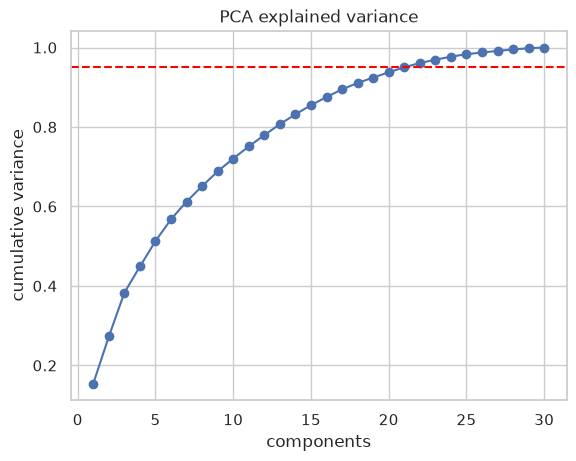

components for 95% variance: 21


,RF,LogReg
PCA 10,0.9464,0.8966
PCA 15,0.9500,0.9104
PCA 21,0.9547,0.9123


In [10]:
pca = PCA(random_state=42).fit(X_train)
cum = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, len(cum) + 1), cum, "o-"); plt.axhline(0.95, color="red", ls="--")
plt.xlabel("components"); plt.ylabel("cumulative variance"); plt.title("PCA explained variance"); plt.show()

n95 = int(np.argmax(cum >= 0.95)) + 1
rows = {}
for k in [10, 15, n95]:
    Z = pd.DataFrame(PCA(k, random_state=42).fit_transform(X_train))
    rows[f"PCA {k}"] = {"RF": cv_f1(rf(), Z), "LogReg": cv_f1(LogisticRegression(max_iter=1000), Z)}
print("components for 95% variance:", n95)
pd.DataFrame(rows).T.round(4)

> **Reading the output:** 21 components are needed for 95% of the variance, and PCA hurts: RF 0.9547 at 21 components vs 0.9650 on raw features, LogReg 0.912 vs 0.930. PCA mixes the categorical codes and loses the splits that matter, so we skip it.

## 8. Compare feature sets head-to-head
Same models, same folds, different inputs.

In [11]:
KEEP_09 = [c for c in X_train.columns if c not in redundant_at(0.9)]
sets = {
    "all original": list(X_train.columns),
    "no redundant (>0.9)": KEEP_09,
    "top 10 (avg rank)": ranking.index[:10].tolist(),
    "top 15 (avg rank)": ranking.index[:15].tolist(),
    "top 20 (avg rank)": ranking.index[:20].tolist(),
}
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=15).fit(pd.get_dummies(X_train.astype(str)).astype(int), y_train)
rows = {}
for name, cols in sets.items():
    rows[name] = {"n_features": len(cols), "RF": cv_f1(rf(), X_train[cols]), "LogReg": cv_f1(lr(), X_train[cols])}
rows["all original + new"] = {"n_features": X_new.shape[1], "RF": cv_f1(rf(), X_new), "LogReg": cv_f1(lr(), X_new)}
rows["no redundant + new"] = {"n_features": len(KEEP_09) + len(new_cols),
                              "RF": cv_f1(rf(), X_new[KEEP_09 + new_cols]), "LogReg": cv_f1(lr(), X_new[KEEP_09 + new_cols])}
compare = pd.DataFrame(rows).T
compare["avg_f1"] = compare[["RF", "LogReg"]].mean(axis=1)
compare = compare.sort_values("avg_f1", ascending=False)
compare.round(4)

,n_features,RF,LogReg,avg_f1
all original,30.0,0.9650,0.9302,0.9476
no redundant (>0.9),29.0,0.9638,0.9301,0.9470
all original + new,35.0,0.9641,0.9283,0.9462
top 20 (avg rank),20.0,0.9628,0.9296,0.9462
no redundant + new,34.0,0.9637,0.9286,0.9461
top 15 (avg rank),15.0,0.9584,0.9232,0.9408
top 10 (avg rank),10.0,0.9357,0.9193,0.9275


> **Reading the output:** All original features score best on average (RF 0.9650, avg 0.9476). Dropping redundant ones or adding engineered ones changes F1 by less than 0.001. Cutting to 10 features costs about 3 points of RF F1 (0.9357).

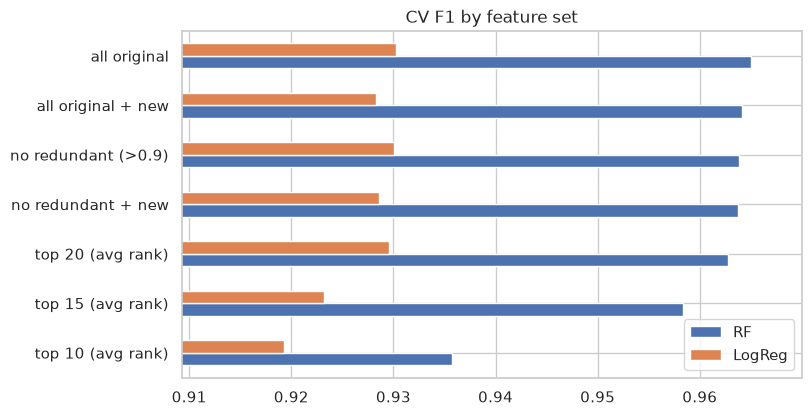

In [12]:
compare[["RF", "LogReg"]].sort_values("RF").plot(kind="barh", figsize=(8, 4.5))
plt.xlim(compare[["RF", "LogReg"]].min().min() - 0.01, compare[["RF", "LogReg"]].max().max() + 0.005)
plt.title("CV F1 by feature set"); plt.show()

> **Reading the output:** The bars are almost level for 20-35 features and fall only for the 15- and 10-feature sets. Differences of 0.001 are within fold noise, so the extra features are neither harmful nor useful.

## 9. Choose and save
We pick the set with the best average F1. The same transformation is applied to train and test.

In [13]:
best_name = compare.index[0]
print("chosen:", best_name)
if "new" in best_name:
    base_cols = KEEP_09 if "no redundant" in best_name else list(X_train.columns)
    FINAL = base_cols + new_cols
else:
    FINAL = sets[best_name]
print(f"{len(FINAL)} features")

Xtr_f, Xte_f = add_features(X_train)[FINAL], add_features(X_test)[FINAL]
Xtr_f.assign(**{TARGET: y_train}).to_csv(IN / "train_fe.csv", index=False)
Xte_f.assign(**{TARGET: y_test}).to_csv(IN / "test_fe.csv", index=False)
(IN / "features.json").write_text(json.dumps({"features": FINAL, "engineered": [c for c in new_cols if c in FINAL]}, indent=2))
print("saved train_fe.csv, test_fe.csv, features.json")

chosen: all original
30 features
saved train_fe.csv, test_fe.csv, features.json


> **Reading the output:** Chosen set: all 30 original features. Simple wins because no tested change gave a gain beyond noise. Train and test CSVs plus `features.json` are saved for notebook 04.

## Takeaways
- Two features (`SSLfinal_State`, `URL_of_Anchor`) do most of the work, and four ranking methods agree.
- No tested trick beat the raw 30 features: pruning, one-hot, PCA and the new count features all gave equal or lower F1.
- Rule of thumb confirmed: try the simple option first and keep a change only if CV proves it helps.
- Output for the next step: `train_fe.csv`, `test_fe.csv`, `features.json`.